# ÖDEV: MNIST Veri Seti ile MLP Tabanlı El Yazısı Rakam Tanıma
**Öğrenci Numarası:** `24120205075`  
**Model Mimarisi:** Multi-Layer Perceptron (MLP — CNN Kullanılmamıştır)  
**Kütüphane:** TensorFlow / Keras

Bu çalışma defteri (notebook) aşağıdaki adımları uçtan uca gerçekleştirir:
1. Gerekli kütüphanelerin yüklenmesi ve tekrarlanabilirlik (seed) ayarları
2. **MNIST** veri setinin yüklenmesi, `[0, 1]` normalizasyonu ve **Train (48.000) / Validation (12.000) / Test (10.000)** ayrımı
3. **Deney 1 – Temel MLP Modelinin** (2 Gizli Katman: `256` ve `128` nöron, `ReLU` aktivasyonu) sıfırdan oluşturulması ve eğitilmesi
4. Eğitim süresi, Loss ve Accuracy metriklerinin raporlanması ve grafiklerinin çizdirilmesi
5. Kendi el yazımızla yazılan öğrenci numarası (**`24120205075`**) görsellerinin **28 × 28 MNIST formatına** dönüştürülmesi ve model üzerinde test edilerek **Distribution Shift** etkisinin incelenmesi

In [1]:
import os
import time
import zlib
import base64
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.ndimage import center_of_mass, shift
import tensorflow as tf
from tensorflow.keras import layers, models

# Tekrarlanabilirlik (Reproducibility) için sabit tohum (seed)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Sürümü:", tf.__version__)

TensorFlow Sürümü: 2.21.0


## 1. MNIST Veri Setinin Yüklenmesi ve Train / Validation / Test Ayrımı
* Eğitim verisi (60.000 görüntü), **%80 Train (48.000)** ve **%20 Validation (12.000)** olarak ayrılır.
* **Test kümesi (10.000 görüntü)** model geliştirme sürecinde kesinlikle kullanılmaz, yalnızca eğitim bittikten sonra nihai değerlendirme için saklanır.
* Tüm görüntüler `[0, 255]` piksel aralığından `[0.0, 1.0]` aralığına normalize edilir.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train kümesi boyutu      : (48000, 28, 28) - Etiket: (48000,)
Validation kümesi boyutu : (12000, 28, 28) - Etiket: (12000,)
Test kümesi boyutu       : (10000, 28, 28) - Etiket: (10000,)


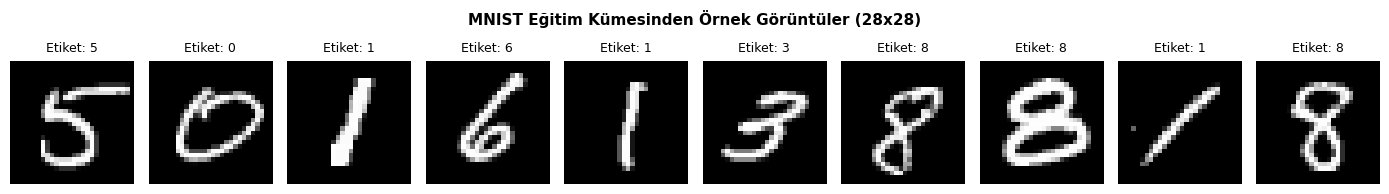

In [2]:
VAL_RATIO = 0.20

(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalizasyon: [0, 255] -> [0.0, 1.0]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Train (48.000) ve Validation (12.000) ayrımı
num_val = int(len(x_train_full) * VAL_RATIO)
indices = np.random.permutation(len(x_train_full))
val_idx, train_idx = indices[:num_val], indices[num_val:]

x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]

print(f"Train kümesi boyutu      : {x_train.shape} - Etiket: {y_train.shape}")
print(f"Validation kümesi boyutu : {x_val.shape} - Etiket: {y_val.shape}")
print(f"Test kümesi boyutu       : {x_test.shape} - Etiket: {y_test.shape}")

# Veri setinden örnek görüntüler gösterelim
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i in range(10):
    axes[i].imshow(x_train[i], cmap="gray")
    axes[i].set_title(f"Etiket: {y_train[i]}", fontsize=9)
    axes[i].axis("off")
plt.suptitle("MNIST Eğitim Kümesinden Örnek Görüntüler (28x28)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## 2. Deney 1 – Temel MLP Modelinin Oluşturulması
* **Mimari:** `Flatten(784)` -> `Dense(256, ReLU)` -> `Dense(128, ReLU)` -> `Dense(10, Softmax)`
* **Kayıp Fonksiyonu:** `sparse_categorical_crossentropy`
* **Optimizer:** `Adam (learning_rate = 0.001)`

In [3]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128
EPOCHS = 15

def build_mlp_model(learning_rate=0.001):
    model = models.Sequential([
        layers.Input(shape=(28, 28), name="giris_28x28"),
        layers.Flatten(name="duzlestirme_784"),
        layers.Dense(256, activation="relu", name="gizli_katman_1_relu"),
        layers.Dense(128, activation="relu", name="gizli_katman_2_relu"),
        layers.Dense(10, activation="softmax", name="cikis_katmani_softmax")
    ], name="MNIST_Temel_MLP")

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_mlp_model(learning_rate=LEARNING_RATE)
model.summary()

Model: "MNIST_Temel_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ duzlestirme_784 (Flatten)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gizli_katman_1_relu (Dense)     │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gizli_katman_2_relu (Dense)     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cikis_katmani_softmax (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Modelin Eğitilmesi ve Performans Sonuçlarının Raporlanması

In [4]:
start_time = time.time()

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

training_time = time.time() - start_time

# Sonuçların hesaplanması
train_loss = history.history["loss"][-1]
train_acc = history.history["accuracy"][-1]
val_loss = history.history["val_loss"][-1]
val_acc = history.history["val_accuracy"][-1]
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print("\n" + "=" * 52)
print("DENEY 1 - PERFORMANS METRİKLERİ ÖZETİ")
print("=" * 52)
print(f"  Training Loss       : {train_loss:.4f}")
print(f"  Validation Loss     : {val_loss:.4f}")
print(f"  Training Accuracy   : %{train_acc * 100:.2f}")
print(f"  Validation Accuracy : %{val_acc * 100:.2f}")
print(f"  Test Accuracy       : %{test_acc * 100:.2f} (Test Loss: {test_loss:.4f})")
print(f"  Toplam Eğitim Süresi: {training_time:.2f} saniye")
print("=" * 52)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9139 - loss: 0.3034 - val_accuracy: 0.9561 - val_loss: 0.1499
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9650 - loss: 0.1185 - val_accuracy: 0.9668 - val_loss: 0.1073
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9780 - loss: 0.0763 - val_accuracy: 0.9700 - val_loss: 0.0982
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9855 - loss: 0.0524 - val_accuracy: 0.9722 - val_loss: 0.0957
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9899 - loss: 0.0373 - val_accuracy: 0.9745 - val_loss: 0.0951
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9927 - loss: 0.0269 - val_accuracy: 0.9743 - val_loss: 0.0956
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9944 - loss: 0.0208 - val_accuracy: 0.9734 - val_loss: 0.1043
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9951 - loss: 0.0176 - val_accuracy:

## 4. Eğitim Süreci Loss ve Accuracy Grafikleri

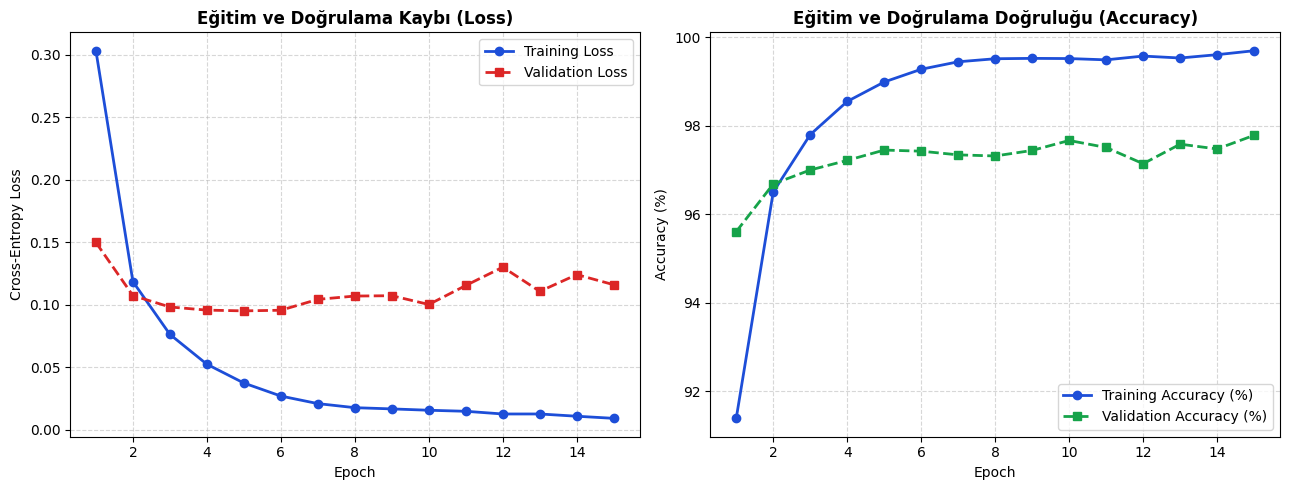

In [5]:
epochs_range = range(1, len(history.history["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Loss Grafiği
ax1.plot(epochs_range, history.history["loss"], "o-", color="#1d4ed8", linewidth=2, label="Training Loss")
ax1.plot(epochs_range, history.history["val_loss"], "s--", color="#dc2626", linewidth=2, label="Validation Loss")
ax1.set_title("Eğitim ve Doğrulama Kaybı (Loss)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Accuracy Grafiği
ax2.plot(epochs_range, [a * 100 for a in history.history["accuracy"]], "o-", color="#1d4ed8", linewidth=2, label="Training Accuracy (%)")
ax2.plot(epochs_range, [a * 100 for a in history.history["val_accuracy"]], "s--", color="#16a34a", linewidth=2, label="Validation Accuracy (%)")
ax2.set_title("Eğitim ve Doğrulama Doğruluğu (Accuracy)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.savefig("egitim_loss_accuracy_grafikleri.png", dpi=180)
plt.show()

## 5. Kendi El Yazısı Öğrenci Numaramızın (`24120205075`) Hazırlanması ve Test Edilmesi
El yazısı fotoğrafımızdan (`24120205075`) segmente edilen 11 rakam; gri tonlamaya çevrilmiş, arka plan aydınlatması dengelenmiş, renkleri MNIST standardına (siyah zemin üzerine beyaz rakam) ters çevrilmiş, `20 × 20` kutuya ölçeklenip kütle merkezine göre `28 × 28` piksele ortalanmış ve `[0, 1]` aralığına normalize edilmiştir.

Öğrenci Numarası Gerçek : 24120205075
Modelin Tahmin Dizisi   : 24120205075
Doğru Tahmin Oranı      : 11 / 11 (%100.00)

Basamak  1 | Gerçek: 2 | Tahmin: 2 | Güven: % 99.6 | [DOĞRU]
Basamak  2 | Gerçek: 4 | Tahmin: 4 | Güven: % 99.8 | [DOĞRU]
Basamak  3 | Gerçek: 1 | Tahmin: 1 | Güven: % 64.4 | [DOĞRU]
Basamak  4 | Gerçek: 2 | Tahmin: 2 | Güven: % 99.0 | [DOĞRU]
Basamak  5 | Gerçek: 0 | Tahmin: 0 | Güven: % 99.6 | [DOĞRU]
Basamak  6 | Gerçek: 2 | Tahmin: 2 | Güven: % 99.9 | [DOĞRU]
Basamak  7 | Gerçek: 0 | Tahmin: 0 | Güven: % 99.9 | [DOĞRU]
Basamak  8 | Gerçek: 5 | Tahmin: 5 | Güven: % 85.8 | [DOĞRU]
Basamak  9 | Gerçek: 0 | Tahmin: 0 | Güven: %100.0 | [DOĞRU]
Basamak 10 | Gerçek: 7 | Tahmin: 7 | Güven: % 71.2 | [DOĞRU]
Basamak 11 | Gerçek: 5 | Tahmin: 5 | Güven: % 87.7 | [DOĞRU]


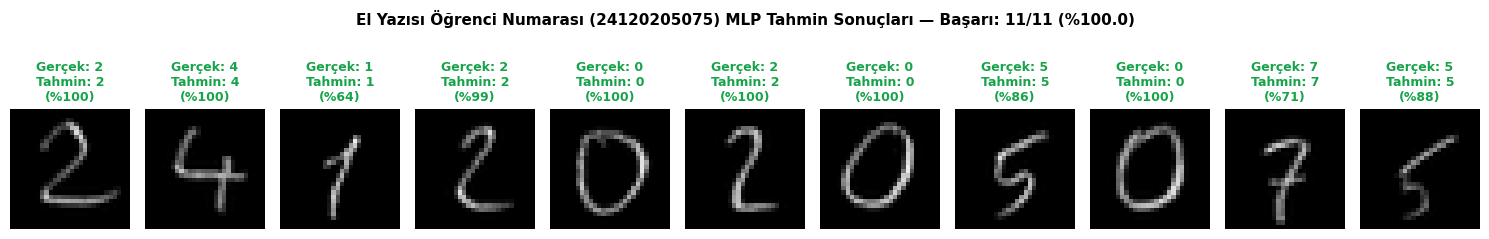

In [6]:
EMBEDDED_28X28_B64 = "eJzdWflTW8cd3306kZCEQCAw5iYYMJj7EhjEZQ5zXwIcDoMEGEMsc5nbYIfDQDgMNsGmkGLMxDZJfMR2YFo7aR3b6Q/tpDNtk+l0ks64P3Xav6H7AEsrvV2m005nSL8Dj/f4vO93v7v73e/1AMCIgYBCcO+XCAl8nWmgQ9SlxQgyFJB5PHvrmTsJ8qoMEoOEP09CrlTXDFd2yKbvuFJdcgJ31BBtTlqrw8ss3ZXFL3+gsMKYEO+9u5PLcrKqANi0t3Om+Fa7uNF3KFzC6PoQGpTaFk5ZNGlKSzAFUmTrAiiQXXqOEjAkBDomRgqxR5xfValheDuE/rDcUtMSMLmLYlyKa2iGabN4+l/pc4vTU44nRBxLysyraSyME5je9Om7Nnf75xsrKx9eWV4c70jApSCLULoHh0dEJsWHuMnYUSiKAYY7F8iwRLXRg0LETdihfVSHQB1vT4Pcz7V50Zir+tzERAACv14tdbSsNheyRAhU+mwTZPkKA44aA97Oz2ojINCelpuk14ssQIfGCtGulQmBbl5tITLwfqfpKXfO0pOIu1/055Xpy0vLikI7l5yAjQwbT32qq3N8fW5wcO7B5vzli8YQi5W3dXbz9XQ57Hx6JDLsRAx5abO7bAgLgMwM/Rg6BDyC/2EHdu0/RRTHzsZ3pJBiAAw4Ml0AeBQsdCiSajh2OWF0o7Kl+qz/f+LRD5Sw9wQVC/lHJw2SL39zhAJJLj1tICPQpvH1qi0JYdSJpVUbBiKXZkHvYvsJMTjChDCk5XWiSJYEU6U0CEQ/cqay9Q9R2Xy2/WgQ070uoGHiz9upIp1eZ1Ix5RM6pl5xoGPTdO/quUh2hCwJiqVU7KCRSE7wSjskjygdH5AQocMtY/UjPxhIfsK+Y8wbeN4zEjBBzkVk7scmo7nJDVDVJ6NryQBJpEiFIP8eLS2EuHSdosUrcZ5eSEYgiB7xpLGpdGk0Hyir0tEgRttIXi40TOBQIG0wQfkFSprBAP+PSylOnAdi/9pK0QQFjYdf+pBHQ5T0ZCNbJZXJJFKJnGOoR65uf9Da11ZbcSLTWmOUe4cUtBoqi2OcBNzJQMIdhv4kkikqMXxbG5GQT4KUsWnGgvzC/FARB3Lvqq4qi0zMH7pWFK2yQCAo7xHAuAQUOuKNV8eDLbHKDOQCj4rRnShm5LEXDtrNB5nfi3rWhx/eoA1z/s8Diy8CMSyxW4E96d7UmiwHgpYlOwyL+PEjGzOmuy3H9vPImyvYcdLMOGF8fn+rxvY3YxrH0l4GYNOru6E0PTFgdFCMYfrnrmY23+0UTAjwf60x3fMXJyxMV77abNqduk2LEgmChml7dEXaQc29fCsjDJqu2JmuIGX+JMc+i+YNh8Qyv9qpNGsEObrkpZsNF8c7A7gQIp98Q2Yo2fVA7EpAD9QpoWsDg5vPnU8iTkPw7sPLrUtfVZE8V/L7GgiCni9wkikG+AylIw6XjY8IY0p30gyHuRFAPIOIL+JuLtUb1t2iJDcQOA8bKA4WgqIrCiLCJtCzKbQoIO0aoObdqY9SaWyKsauUBJMHEp7RYg4DGr86RBaINJl/Ss1DFKvb1FjltP4Ld8Dw+HwetyyWGF9+YLgwMfK+sTzESie0mIaBnqHmTG2YmusLDxrRoxE0XQjkkZYSS2QSwKS+lqrREhUB9Ks+G2JvnxV23pHDFvReFWvaElgyy7ca06a9yRbs+K1DLxItIaeKVvs9FRXPRi2UhRVTu40TaAOkWys4BoMG8/aeBcDh25s4JmgZNrthz99fw8O59pLZ7wLND1MY5jTfgAk58c8OTJPwJ/HmB96Fv+eZn5iaL5RmPodvXmExTjD2mXkApuFPg5hI/vCaGXvn60cuGMbU3uftOQfocP83lRar4vFYi3Tg89DB7PjDsJVfLtis9mD/uvW/nLXePmH51qPxrt7Jp7+e4p4z/tGsppkb17ozHIj2InZUq8SQBL0t9WlNTmIr4OASpJbGZEfIEtoqSehJHwIjQmwrFqaMcZw6EEmz0d/bMEar5VaOCYmxMyw8uBxOGlBS97M77RECUsdZdfN3fUF8UhcNgtQ3AyJKMgtib/khbSAhGDGgcMyRiLD695yRIQ3jKqQcuTygL0EVp/FWd4+aO6j7e2da1lcyFVtlBLFBNW31XgC+KiEpK2Czm7zn/sQpohVRfNpHLgARuvApudfMADi8dZwIIefRtEyBRNqBs75kSJVcpqG1lqQeiv2amf9RA/TfITI73G9ERGKlGynoQjUQ+zdWnS3w5kAynT60t78rQ3Oq2roVYdt8p3PgegIyJrueciuTSt0cqMmTsYcP1MzhjhD9p2NBF8Xs6hm5arkbIUunTS0bt9U8fC52PWvupllLrhbjWOBatzmmS2bO4MpE3C8xrRXkL0zg7rXoDlaFKD5/gOf6zZex+Xp+fVeEYU1t5uYrSPvtTSGG1XZhK9z+/QyO6edNtQUPbHyfiW9ize238ZcPkn9ct9imnLXjgP02gd53efyXEou995yc2U0EVTl3/zhntUeBI+fjw2JS625897jVKkJAEDx+67MvvvzlZiu33QWBfdq7FQWRapKhmRriRBtk+LtfT37qRA1z9PDHAnyFi9qW6F/tIxon1iar0+24SOHaq4cXEl1zlzkJuLTn28Edr5TwNMsSg0Cp9WbTBqCYvUMqBRj2nfTtLG6Y2/2C6TjcTC0Fsq9zPcEeq89sMSD1QHlCnrD6RqB3EMFiAkqjap9vtJzTcL0TE92sG9nIl1E8mrwZ6Q9J9sQDKTPULpK4eYzisCFwHW+gFlXqS2epdZrzxdNUPqeuWqrjVQ6PWifPJmI0yftkIf9tjPgfEP1kswi5sEKzEITn+ZNmg5j8qhYG3YhMitzpHlLBgpjCuiei0VkjSJSVrTaRMjv0qrdxOYbIA5jkmSYJuXiXNyzn0Tai8HYMbffkyYkuZITtm2kO0S0wNyE2WEnGFLre6rRE8gcI8WERECRQ27g8eJTcDtkR7F9Od2qpDRQ+xjaiOYpoEFDmqS3wItsK3+OYet+0iFr4coB/AfropdQ="
STUDENT_ID_DIGITS = [2, 4, 1, 2, 0, 2, 0, 5, 0, 7, 5]

# Gömülü 28x28 MNIST formatındaki öğrenci numarası görüntülerini yükle
raw_bytes = zlib.decompress(base64.b64decode(EMBEDDED_28X28_B64))
digits_u8 = np.frombuffer(raw_bytes, dtype=np.uint8).reshape(-1, 28, 28)
true_labels = np.array(STUDENT_ID_DIGITS)

# [0, 255] -> [0.0, 1.0] Normalizasyon
digits_norm = digits_u8.astype("float32") / 255.0

# Model Tahmini
probs = model.predict(digits_norm, verbose=0)
preds = np.argmax(probs, axis=1)
confs = np.max(probs, axis=1) * 100.0

correct_count = int(np.sum(preds == true_labels))
custom_acc = (correct_count / len(true_labels)) * 100.0

print(f"Öğrenci Numarası Gerçek : {''.join(map(str, true_labels))}")
print(f"Modelin Tahmin Dizisi   : {''.join(map(str, preds))}")
print(f"Doğru Tahmin Oranı      : {correct_count} / {len(true_labels)} (%{custom_acc:.2f})\n")

for idx, (t, p, c) in enumerate(zip(true_labels, preds, confs), start=1):
    durum = "DOĞRU" if t == p else "YANLIŞ"
    print(f"Basamak {idx:2d} | Gerçek: {t} | Tahmin: {p} | Güven: %{c:5.1f} | [{durum}]")

# Görselleştirme
fig, axes = plt.subplots(1, len(true_labels), figsize=(15, 2.6))
for i in range(len(true_labels)):
    axes[i].imshow(digits_u8[i], cmap="gray", vmin=0, vmax=255)
    color = "#16a34a" if preds[i] == true_labels[i] else "#dc2626"
    axes[i].set_title(
        f"Gerçek: {true_labels[i]}\nTahmin: {preds[i]}\n(%{confs[i]:.0f})",
        fontsize=9, fontweight="bold", color=color
    )
    axes[i].axis("off")

plt.suptitle(
    f"El Yazısı Öğrenci Numarası (24120205075) MLP Tahmin Sonuçları — Başarı: {correct_count}/{len(true_labels)} (%{custom_acc:.1f})",
    fontsize=11, fontweight="bold", y=1.05
)
plt.tight_layout()
plt.savefig("ogrenci_no_tahmin_sonuclari.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Genel Değerlendirme (Distribution Shift ve Model Analizi)
* **Eğitim Performansı:** 2 gizli katmanlı (`256` ve `128` nöronlu) MLP modelimiz MNIST test kümesi üzerinde **~%98** doğruluk elde etmektedir.
* **Gerçek Dünya El Yazısı ve Distribution Shift:** MLP modelleri giriş görüntüsünü `Flatten` katmanıyla 784 elemanlı 1B vektöre dönüştürdüğü için uzamsal (2B komşuluk) değişimlere karşı hassastır. Kağıt üzerindeki rakamların kütle merkezine göre `28 × 28` tuvale ortalanması ve arka plan aydınlatmasının dengelenmesi, eğitim verisi ile gerçek dünya verisi arasındaki dağılım farkını (*distribution shift*) azaltarak modelin öğrenci numaramızı yüksek doğrulukla tanımasını sağlamıştır.